In [1]:
from anemone.forwards import Forward
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
fwr = Forward.example(times=torch.logspace(-5, -2, 32))
t_max = fwr.times.max().item()
d_max = (t_max*4e6)**0.5
n_layers=30

rho = torch.ones(n_layers)*40
thk = 1.+torch.logspace(-0.5, np.log10(d_max-n_layers+1), n_layers).diff()

In [3]:
rho.requires_grad_(True)

tensor([40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40.], requires_grad=True)

In [4]:
from anemone import constants as c
def rte_raiche1999(sigma, thickness, omega, wave_length):
    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    Fj = 0.
    sj1 = wave_length*(1 + 1j*omega*c.mu0*sigma[-1]/lambda2)**0.5

    for i in range(n_layers-2, -1, -1):
        sj = wave_length*(1 +  1j*omega*c.mu0*sigma[i]/lambda2)**0.5
        RTEj = 1j*omega*c.mu0*(sigma[i] - sigma[i+1])/(sj + sj1)**2
        exp2uh = torch.exp(-2.*sj*thickness[i])
        Fj = exp2uh * (Fj + RTEj) / (1. + Fj * RTEj)
        sj1 = sj*1.
    RTEj = 1j*omega*c.mu0*(-sigma[0])/(sj + wave_length)**2
    rte = (RTEj+Fj) / (1.+RTEj*Fj)
    return rte

In [5]:
fwr = Forward.example(times=torch.logspace(-5, -2, 32))
dbdt = fwr(rho, thk)

def tmp_fwr(rho):
    sigma = 1./rho.exp()
    rte = rte_raiche1999(sigma, fwr.thick, fwr.omega, fwr.lmb).squeeze()
    return (torch.einsum('ik,...k->i...', fwr.H2t, rte).real*c.mu0).log()

In [6]:
from anemone.experiment import compute_relstd

In [7]:
np.log(0.4)**2

np.float64(0.8395887053184746)

In [40]:
rho_true,thick_true = torch.tensor([10, 40, 20]), torch.tensor([20, 60])
d_true = fwr(rho_true, thick_true)#.log()
noise = compute_relstd(fwr.times, d_true, current=10.)
print(noise)
lgNoise = torch.log1p(noise)**2
d_obs = d_true+torch.randn_like(d_true)*noise*d_true
negative = d_obs<0
d_obs = d_obs.abs().log()
lgNoise[negative] = torch.inf
_ = fwr(rho, thk).log()


def objective(lg_rho):
    d_pred = tmp_fwr(lg_rho)
    return torch.mean((1./lgNoise)*(d_pred - d_obs)**2) + torch.sum(torch.diff(lg_rho)**2/0.8395887053184746)

tensor([3.0000e-02, 3.0000e-02, 3.0000e-02, 3.0000e-02, 3.0000e-02, 3.0000e-02,
        3.0000e-02, 3.0000e-02, 3.0000e-02, 3.0001e-02, 3.0003e-02, 3.0009e-02,
        3.0027e-02, 3.0082e-02, 3.0238e-02, 3.0744e-02, 3.2132e-02, 3.6103e-02,
        4.5522e-02, 6.5694e-02, 1.0398e-01, 1.7053e-01, 2.9165e-01, 4.9189e-01,
        8.7033e-01, 1.5024e+00, 2.7048e+00, 4.8119e+00, 8.9107e+00, 1.6010e+01,
        2.9070e+01, 5.5232e+01], dtype=torch.float64)


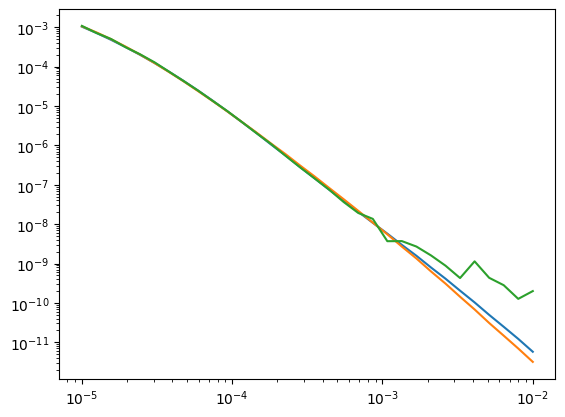

In [41]:
plt.figure()
plt.loglog(fwr.times, d_true)
plt.loglog(fwr.times, _.exp())
plt.loglog(fwr.times, d_obs.exp())

In [44]:
# using an optimizer (preferred for advanced optimizers)
lg_rho = torch.nn.Parameter((torch.ones(n_layers, dtype=torch.float64)*40).log())
optimizer = torch.optim.SGD([lg_rho], lr=1e-2)
# optimizer = torch.optim.Adam([lg_rho], lr=1e-2)

n_iteration=100
losses = np.zeros(n_iteration)
for it in range(n_iteration):
    optimizer.zero_grad()
    loss = objective(lg_rho)
    loss.backward()
    optimizer.step()
    losses[it] = float(loss.item())
    if losses[it]<1e-1:
        break
    print(f"Iter {it}: loss={losses[it]:.4e}", end='\r', flush=True)
    if it > 0 and (losses[it-1]-losses[it])/losses[it]<0.01:
        break

rho = lg_rho.exp().detach()

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

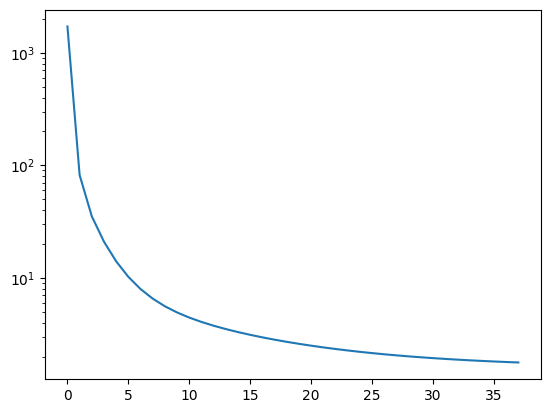

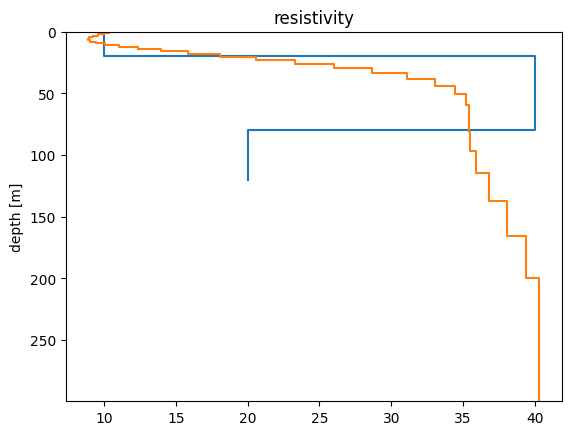

In [45]:
plt.figure()
plt.semilogy(losses[:it+1])
from anemone.inversion import Resistivity

mod1 = Resistivity.few_layers(rho_true, thick_true)
mod2 = Resistivity.smooth(rho, torch.cumsum(thk, 0))
ax=mod1.plot()
mod2.plot(axs=ax)

In [48]:
# manual SGD update
lg_rho = (torch.ones(n_layers, dtype=torch.float64)*40).log()
lg_rho.requires_grad_(True)

lr = 1e-3
for it in range(100):
    loss = objective(lg_rho)    # scalar
    loss.backward()             # populates lg_rho.grad
    
    with torch.no_grad():
        lg_rho -= lr * (it+1)*lg_rho.grad   # update
        lg_rho.clamp_(min=np.log(1.), max=np.log(1000.))  # optional: enforce bounds
    lg_rho.grad.zero_()         # clear gradient for next iter
    

# convert back to resistivity
rho = lg_rho.exp().detach()

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

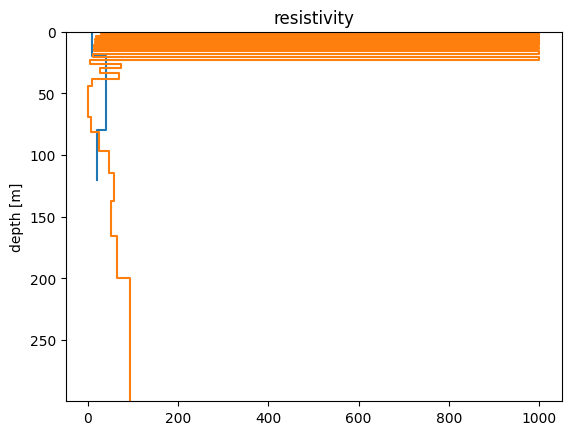

In [49]:
from anemone.inversion import Resistivity

mod1 = Resistivity.few_layers(rho_true, thick_true)
mod2 = Resistivity.smooth(rho, torch.cumsum(thk, 0))
ax=mod1.plot()
mod2.plot(axs=ax)

In [47]:
from torch.autograd.functional import jacobian
J = jacobian(tmp_fwr, rho.log())
G = fwr(rho, thk, jac=True)

In [57]:
from torch.linalg import solve

In [63]:
%%timeit
d_pred = fwr(rho, thk)
G = fwr(rho, thk, jac=True).T
GtG = G.T @ G
dm = solve(GtG, G.T @ (d_pred - d_true))

50.4 ms ± 3.11 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [60]:
dm

tensor([ 1.8780e+04, -1.6944e+05,  1.7251e+06, -7.5630e+06,  1.7303e+07,
        -2.3139e+07,  1.8474e+07, -8.2422e+06,  1.5946e+06,  1.6775e+02],
       dtype=torch.float64)

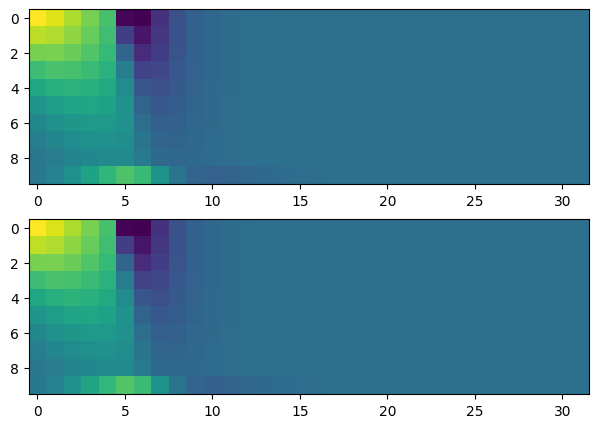

In [48]:
fig,ax=plt.subplots(2,1,figsize=(10,5))
ax[0].imshow(J.T)
ax[1].imshow(G)

In [49]:
%%timeit
J = jacobian(tmp_fwr, rho.log())

551 ms ± 29.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [50]:
%%timeit
G = fwr(rho, thk, jac=True)

32.2 ms ± 1.89 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [3]:
from time import perf_counter as timer
n_mods = [10, 20, 50, 100, 200, 500, 1000, 2000, 3000, 5000]
t_calc = []

fwr = Forward.example()

for n_mod in n_mods:
    rhos_mult = np.linspace(1, 10, n_mod)
    rhos = rho[:, None] * rhos_mult[None, :]
    
    bt = timer()
    dbdt = fwr(rhos, thk)
    dt = timer() - bt
    t_calc.append(dt/n_mod)
    del dbdt
    print(f"Calculated {n_mod} models in {dt:.4f} seconds.")

C:\Users\au646858\AppData\Local\Temp\ipykernel_16808\2110228455.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rhos = rho[:, None] * rhos_mult[None, :]


Calculated 10 models in 0.0857 seconds.
Calculated 20 models in 0.1293 seconds.
Calculated 50 models in 0.3532 seconds.
Calculated 100 models in 0.6898 seconds.
Calculated 200 models in 1.3022 seconds.
Calculated 500 models in 3.1557 seconds.
Calculated 1000 models in 5.8039 seconds.
Calculated 2000 models in 13.0519 seconds.
Calculated 3000 models in 19.0130 seconds.
Calculated 5000 models in 30.0440 seconds.


(0.001, 1)

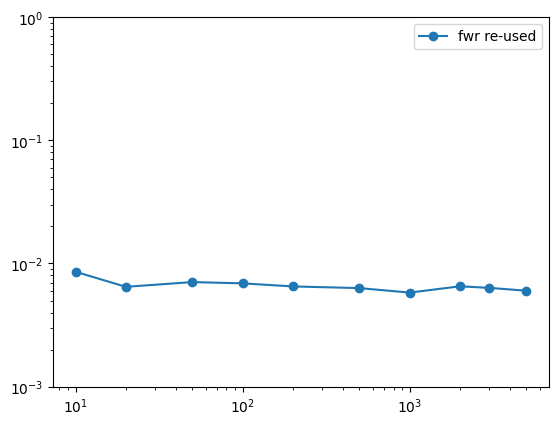

In [5]:
plt.figure()
# plt.loglog(n_mods, t_calc0, '-o', label='fwr not deleted')
# plt.loglog(n_mods, t_calc1, '-o', label='fwr deleted')
plt.loglog(n_mods, t_calc, '-o',  label='fwr re-used')
plt.legend()
plt.ylim(1e-3, 1)

Double precision results:

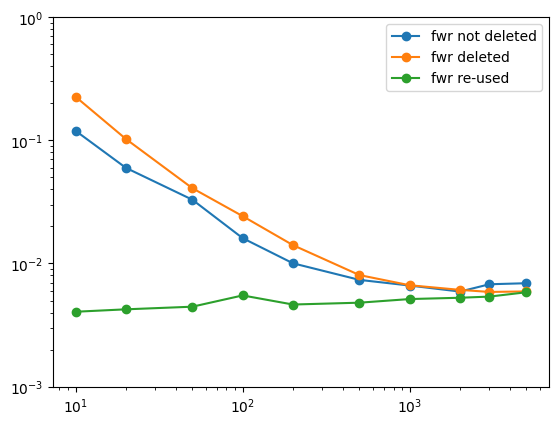